In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from imblearn.over_sampling import RandomOverSampler


the col names 
the dataframe csv
class = lcassification

In [4]:
cols=['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
df=pd.read_csv("diabetes.csv", header=0, names=cols)
def sigmoid(z):
    sig_val=1/(1+np.exp(-z))
    return sig_val

def initialize_weights(row_vector):
    w= np.zeros_like(row_vector, dtype=float)
    b=0.0
    return w,b

or we can use if else 

df['class']=df['class'].map({'g':0,'h':1})

df['class']=(df['class']=='g).astype(int)

In [5]:
# df['class'] = (df['class']=='g').astype(int)

# compute log-loss

In [ ]:
def logloss(y_t, y_p):
    epsilon=1e-15
    y_p=np.clip(y_p, epsilon, 1-epsilon)
    n=y_t.shape[0]
    indi_loss=np.dot(y_t, np.log(y_p))+np.dot((1 - y_t), np.log(1 - y_p))
    loss=(-1/n)*np.sum(indi_loss)
    return loss


def accuracy(y_t, y_p):
    predictions = (y_p>=0.5).astype(int)
    return np.mean(predictions==y_t)

# predict function

In [7]:
def pred(w,b, X):
    N = len(X)
    predict = []
    for i in range(N):
        z=np.dot(w,X[i])+b
        predict.append(sigmoid(z))
    return np.array(predict)

In [8]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


# Train, validation, test

In [12]:
len(df)

768

In [9]:

train, valid, test = np.split(df.sample(frac=1), [int(0.7*len(df)), int(0.9*len(df))])
train = pd.DataFrame(train, columns=df.columns)
valid = pd.DataFrame(valid, columns=df.columns)
test = pd.DataFrame(test, columns=df.columns)

In [10]:
def scale_dataset(dataframe):
    x=dataframe[dataframe.columns[:-1]].values
    y=dataframe[dataframe.columns[-1]].values
    data=np.hstack((x, np.reshape(y, (-1, 1))))
    return data, x, y

In [17]:
x=np.array([[1,2,3]])
x[0].shape,x.shape

((), (3,))

In [ ]:
train, X_train, y_train=scale_dataset(train)
valid, X_valid, y_valid=scale_dataset(valid)
test, X_test, y_test=scale_dataset(test)
test.shape, X_test.shape, y_test.shape

((77, 9), (77, 8), (77,))

In [ ]:
from tqdm import tqdm
def regularization_gradient(weights, alpha, regularization):
    if regularization == 'l1':
        return alpha * np.sign(weights)

    elif regularization == 'l2':
        return alpha * weights

    return np.zeros_like(weights)
def regularization_penalty(weights, alpha, regularization):
    if regularization == 'l1':
        return alpha * np.sum(np.abs(weights))

    elif regularization=='l2':
        return (alpha / 2) * np.sum(weights ** 2)

    return 0.0

def gradient_dw(x, y, w, b, alpha, N, regularization=None):
    data_gradient=x*(y-sigmoid(np.dot(w, x)+b))
    penalty_gradient=regularization_gradient(w, alpha, regularization)/N
    dw=data_gradient-penalty_gradient
    return dw

def gradient_db(x,y,w,b):
     db= y-sigmoid(np.dot(w,x)+b)
     return db

def train(
    X_train, y_train, X_valid, y_valid,
    epochs, alpha, eta0,
    regularization=None
):
    train_loss=[]
    valid_loss=[]
    train_accuracy=[]
    valid_accuracy=[]
    weights, bias=initialize_weights(X_train[0])
    n=X_train.shape[0]

    for epoch in tqdm(range(epochs)):
        for i in range(n):
            # probability=sigmoid(np.dot(weights, X_train[i])+bias)
            # error=y_train[i]-probability
            # penalty_gradient = regularization_gradient(weights, alpha, regularization) if regularization else np.zeros_like(weights)
            # weights+= eta0*(X_train[i]*error-penalty_gradient/n)  eta(x*(y-sigmoid(np.dot(w,x)+b)))-((alpha/N)*w)
            # bias+= eta0*error
            dw = gradient_dw(X_train[i], y_train[i], weights, bias, alpha, n, regularization)
            db = gradient_db(X_train[i], y_train[i], weights, bias)

            weights += eta0 * dw
            bias += eta0 * db

        train_probability = pred(weights, bias, X_train)
        valid_probability = pred(weights, bias, X_valid)
        penalty = regularization_penalty(weights, alpha, regularization)/n if regularization else 0.0

        train_loss.append(logloss(y_train, train_probability)+penalty)
        valid_loss.append(logloss(y_valid, valid_probability)+penalty)
        train_accuracy.append(accuracy(y_train, train_probability))
        valid_accuracy.append(accuracy(y_valid, valid_probability))

    return weights, bias, train_loss, valid_loss, train_accuracy, valid_accuracy

alpha = 0.1
eta0 = 0.001
epochs = 50
w, b, train_loss, valid_loss, train_accuracy, valid_accuracy = train( X_train, y_train, X_valid, y_valid, epochs, alpha, eta0)


100%|██████████| 50/50 [00:00<00:00, 78.00it/s]


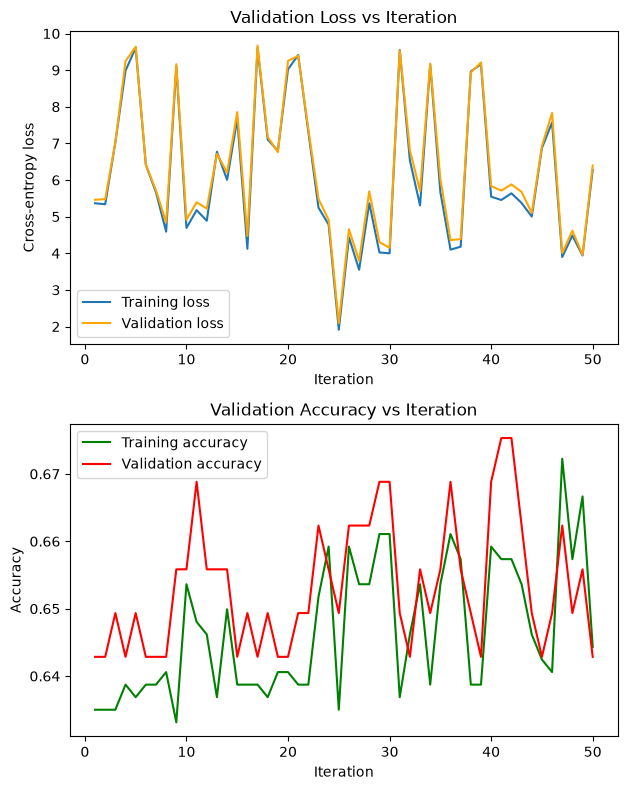

Final test loss: 4.5537
Final test accuracy: 0.7403


In [20]:
iterations = range(1, epochs + 1)

test_probability = pred(w, b, X_test)
test_loss = logloss(y_test, test_probability)
test_accuracy = accuracy(y_test, test_probability)

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.plot(iterations, train_loss, label='Training loss')
plt.xlabel('Iteration')
plt.ylabel('Cross-entropy loss')
plt.title('Training Loss vs Iteration')
plt.legend()

plt.subplot(2, 2, 1)
plt.plot(iterations, valid_loss, label='Validation loss', color='orange')
plt.xlabel('Iteration')
plt.ylabel('Cross-entropy loss')
plt.title('Validation Loss vs Iteration')
plt.legend()

plt.subplot(2, 2, 3)
plt.plot(iterations, train_accuracy, label='Training accuracy', color='green')
plt.xlabel('Iteration')
plt.ylabel('Accuracy')
plt.title('Training Accuracy vs Iteration')
plt.legend()

plt.subplot(2, 2, 3)
plt.plot(iterations, valid_accuracy, label='Validation accuracy', color='red')
plt.xlabel('Iteration')
plt.ylabel('Accuracy')
plt.title('Validation Accuracy vs Iteration')
plt.legend()

plt.tight_layout()
plt.show()

print(f'Final test loss: {test_loss:.4f}')
print(f'Final test accuracy: {test_accuracy:.4f}')

# confusion martix


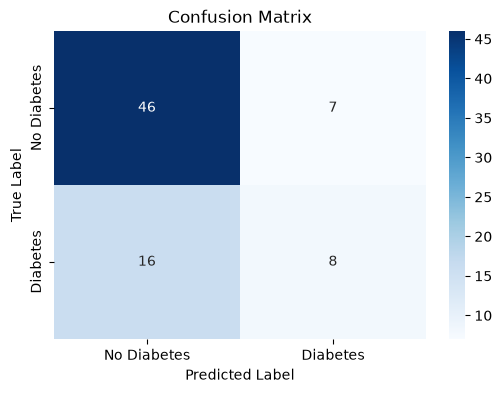

In [12]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

test_p =(test_probability>=0.5).astype(int)
cm=confusion_matrix(y_test, test_p)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

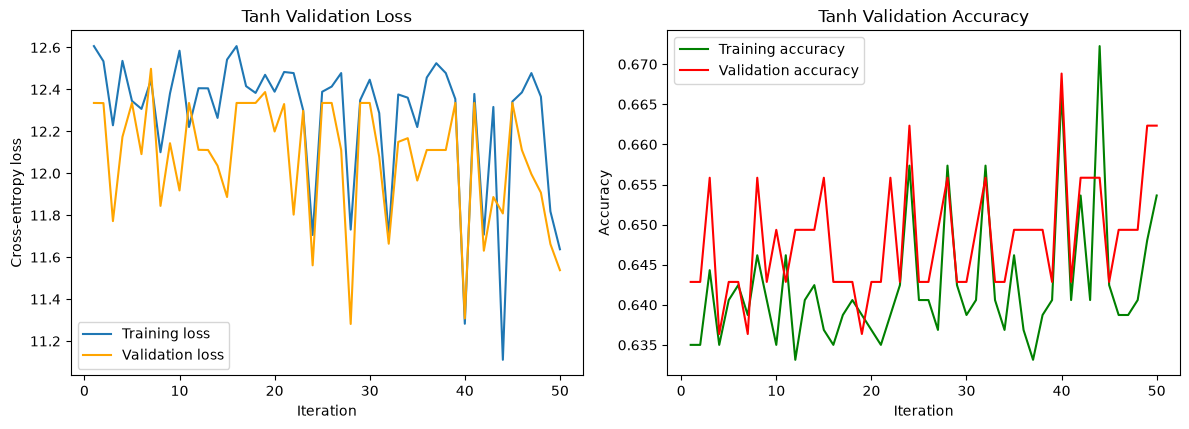

In [26]:
# Part (e): replace sigmoid with tanh and use cross-entropy loss

def tanh(z):
    return np.tanh(z)


def pred_tanh(w, b, X):
    probabilities = []
    for row in X:
        z = np.dot(w, row) + b
        probabilities.append((tanh(z) + 1) / 2)
    return np.array(probabilities)


def tanh_loss(y_true, y_pred):
    epsilon=1e-15
    probabilities=np.clip(y_pred, epsilon, 1 - epsilon)
    return -np.mean(y_true*np.log(probabilities)+(1-y_true)*np.log(1-probabilities)
    )


def tanh_accuracy(y_true, y_pred):
    return np.mean((y_pred >= 0.5) == y_true)


def train_tanh(X_train, y_train, X_valid, y_valid, epochs, learning_rate):
    train_loss = []
    valid_loss = []
    train_accuracy = []
    valid_accuracy = []

    weights, bias = initialize_weights(X_train[0])
    n = X_train.shape[0]

    for epoch in range(epochs):
        for i in range(n):
            z = np.dot(weights, X_train[i])+bias
            probability = (tanh(z)+1)/2
            error = y_train[i] - probability
            weights += 2*learning_rate*X_train[i]*error
            bias += 2*learning_rate*error

        train_pred = pred_tanh(weights, bias, X_train)
        valid_pred = pred_tanh(weights, bias, X_valid)

        train_loss.append(tanh_loss(y_train, train_pred))
        valid_loss.append(tanh_loss(y_valid, valid_pred))

        train_accuracy.append(tanh_accuracy(y_train, train_pred))
        valid_accuracy.append(tanh_accuracy(y_valid, valid_pred))

    return weights, bias, train_loss, valid_loss, train_accuracy, valid_accuracy


epochs = 50
learning_rate = 0.01

w_tanh, b_tanh, train_loss_tanh, valid_loss_tanh, train_acc_tanh, valid_acc_tanh = train_tanh(
    X_train, y_train, X_valid, y_valid, epochs, learning_rate
)

iterations = range(1, epochs + 1)
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.plot(iterations, train_loss_tanh, label='Training loss')
plt.xlabel('Iteration')
plt.ylabel('Cross-entropy loss')
plt.title('Tanh Training Loss')
plt.legend()

plt.subplot(2, 2,1 )
plt.plot(iterations, valid_loss_tanh, label='Validation loss', color='orange')
plt.xlabel('Iteration')
plt.ylabel('Cross-entropy loss')
plt.title('Tanh Validation Loss')
plt.legend()

plt.subplot(2, 2, 2)
plt.plot(iterations, train_acc_tanh, label='Training accuracy', color='green')
plt.xlabel('Iteration')
plt.ylabel('Accuracy')
plt.title('Tanh Training Accuracy')
plt.legend()

plt.subplot(2, 2, 2)
plt.plot(iterations, valid_acc_tanh, label='Validation accuracy', color='red')
plt.xlabel('Iteration')
plt.ylabel('Accuracy')
plt.title('Tanh Validation Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

/tmp/ipykernel_1199/228687979.py:4: RuntimeWarning: overflow encountered in exp
  sig_val=1/(1+np.exp(-z))


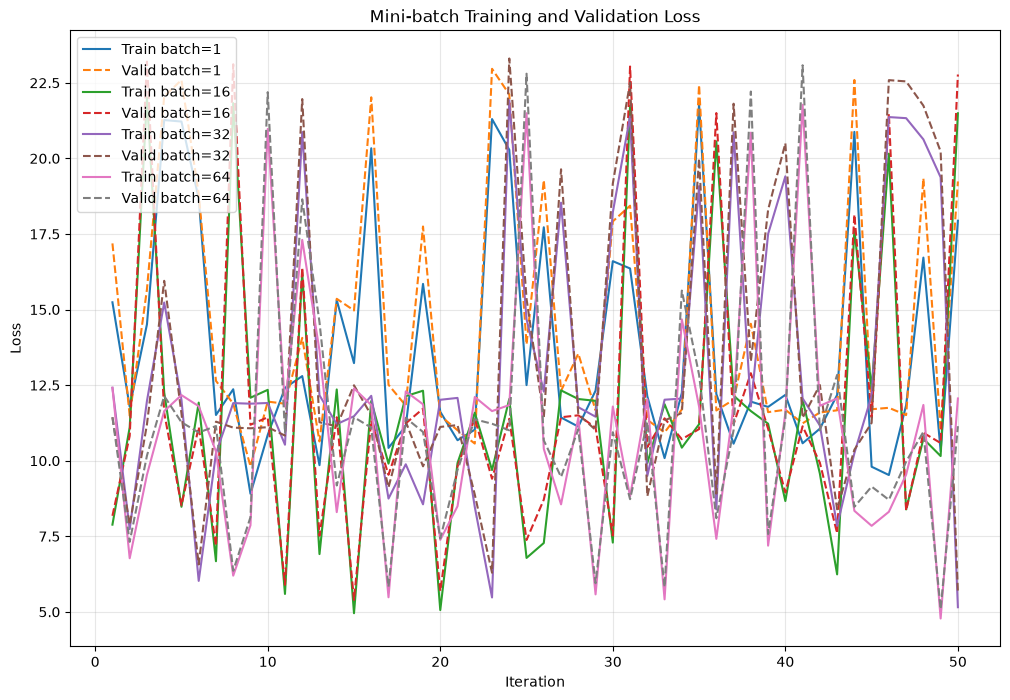

In [14]:
# Part (f): Mini-batch gradient descent
def train_minibatch(X_train, y_train, X_valid, y_valid, epochs, learning_rate, batch_size):
    train_loss = []
    valid_loss = []
    train_accuracy = []
    valid_accuracy = []

    weights, bias = initialize_weights(X_train[0])
    n = X_train.shape[0]

    for epoch in range(epochs):
        indices = np.random.permutation(n)
        X_shuffled = X_train[indices]
        y_shuffled = y_train[indices]

        for start in range(0, n, batch_size):
            end = start + batch_size
            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            probabilities = sigmoid(np.dot(X_batch, weights) + bias)
            errors = y_batch - probabilities

            dw = np.mean(X_batch * errors.reshape(-1, 1), axis=0)
            db = np.mean(errors)

            weights += learning_rate * dw
            bias += learning_rate * db

        train_probability = pred(weights, bias, X_train)
        valid_probability = pred(weights, bias, X_valid)

        train_loss.append(logloss(y_train, train_probability))
        valid_loss.append(logloss(y_valid, valid_probability))
        train_accuracy.append(accuracy(y_train, train_probability))
        valid_accuracy.append(accuracy(y_valid, valid_probability))

    return weights, bias, train_loss, valid_loss, train_accuracy, valid_accuracy


batch_sizes = [1, 16, 32, 64]
mini_batch_results = {}

for batch_size in batch_sizes:
    mini_batch_results[batch_size] = train_minibatch(
        X_train, y_train, X_valid, y_valid, epochs=50, learning_rate=0.01, batch_size=batch_size
    )


plt.figure(figsize=(12, 8))
for batch_size, result in mini_batch_results.items():
    _, _, train_loss_mb, valid_loss_mb, _, _ = result
    plt.plot(range(1, len(train_loss_mb) + 1), train_loss_mb, label=f'Train batch={batch_size}')
    plt.plot(range(1, len(valid_loss_mb) + 1), valid_loss_mb, linestyle='--', label=f'Valid batch={batch_size}')

plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Mini-batch Training and Validation Loss')
plt.legend()
plt.grid(alpha=0.3)
plt.show()